# Brownian Motion: Hitting Time Estimation

Monte Carlo estimate of $\mathbb E[\tau_a \wedge T]$, where $\tau_a = \inf\{t>0 : W_t = a\}$, on a discrete grid with $N$ steps. The closed-form value is
$$\mathbb E[\tau_a \wedge T] = T\Big(1 - \frac{\Gamma(\frac12, \frac{a^2}{2T})}{\sqrt\pi}\Big) + \frac{a^2}{2\sqrt\pi}\,\Gamma\Big(-\frac12, \frac{a^2}{2T}\Big).$$

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import erfc

T, a = 3.0, 1.0
M = 200_000
rng = np.random.default_rng(0)

x = a**2 / (2 * T)
gamma_half = np.sqrt(np.pi) * erfc(np.sqrt(x))
gamma_minus_half = 2 * (np.exp(-x) / np.sqrt(x) - gamma_half)
true_value = T * (1 - gamma_half / np.sqrt(np.pi)) + a**2 / (2 * np.sqrt(np.pi)) * gamma_minus_half
true_value

np.float64(1.9150064877333546)

## Estimator

In [2]:
def estimate_tau(N, M, rng, batch=20_000):
    dt = T / N
    total, total_sq = 0.0, 0.0
    for start in range(0, M, batch):
        m = min(batch, M - start)
        W = np.cumsum(np.sqrt(dt) * rng.standard_normal((m, N)), axis=1)
        hit = W >= a
        tau = np.where(hit.any(axis=1), (hit.argmax(axis=1) + 1) * dt, T)
        total += tau.sum()
        total_sq += (tau**2).sum()
    mean = total / M
    return mean, 1.96 * np.sqrt((total_sq / M - mean**2) / M)

est, ci = estimate_tau(100, M, rng)
print(f"N = 100: {est:.4f} ± {ci:.4f}   true value: {true_value:.4f}   bias: {est - true_value:.4f}")

N = 100: 2.0309 ± 0.0047   true value: 1.9150   bias: 0.1158


## Bias as a function of $N$

Fitted order: -0.498


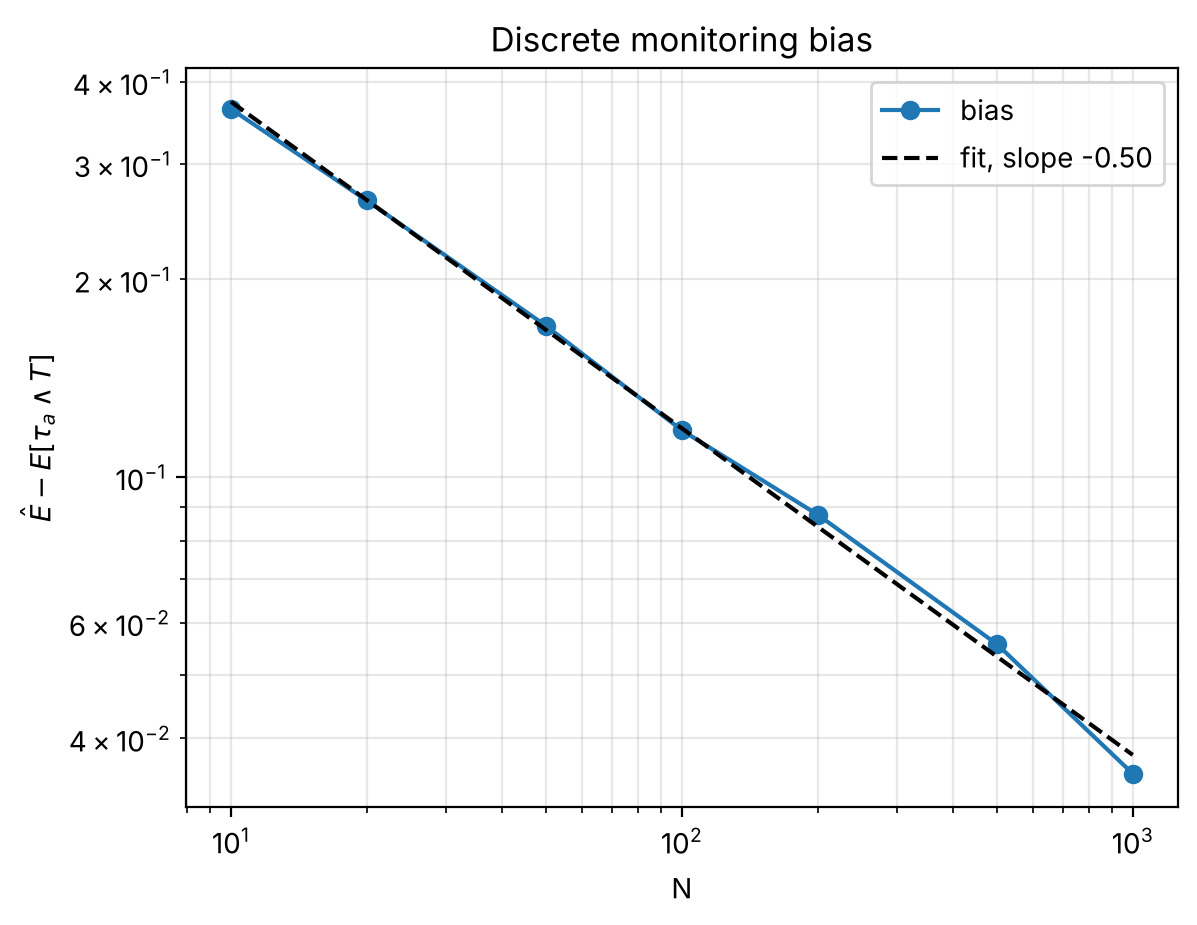

In [3]:
Ns = np.array([10, 20, 50, 100, 200, 500, 1000])
bias = np.array([estimate_tau(N, M, rng)[0] - true_value for N in Ns])
slope, intercept = np.polyfit(np.log(Ns), np.log(bias), 1)
print(f"Fitted order: {slope:.3f}")

plt.loglog(Ns, bias, "o-", label="bias")
plt.loglog(Ns, np.exp(intercept) * Ns**slope, "k--", label=f"fit, slope {slope:.2f}")
plt.xlabel("N"); plt.ylabel(r"$\hat E - E[\tau_a \wedge T]$")
plt.title("Discrete monitoring bias")
plt.legend(); plt.grid(True, which="both", alpha=0.3); plt.show()

The path can cross $a$ between two grid dates without being detected, so the hitting time is overestimated. The bias decreases like $N^{-1/2}$.